# 03 · Comparação de modelos, calibração, limiar e explicabilidade

Guardiã AI · Tech Challenge 5 · grupo fiap-ssp-2025

Treina e compara **Regressão Logística**, **Random Forest** (com busca por algoritmo genético, herança do
Tech Challenge 2) e **HistGradientBoosting** para o alvo `ENCAMINHA_PROTECAO`. O protocolo é o mesmo do script
`guardia.ml.train` (que gera o artefato implantado): 70/30 estratificado, validação de 15% dentro do treino para
limiar, calibração e fitness do GA; o teste é tocado uma única vez.

**Por que não acurácia.** A prevalência é ~28%: "nunca sugerir" acerta 72% das vezes e não ajuda ninguém.
A métrica prioritária é o **recall da classe encaminhada** (deixar de sugerir um encaminhamento custa mais que
sugerir a mais), acompanhada de precisão, F1, PR-AUC e calibração. O limiar operacional maximiza F2 na validação.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

## Rodar o treino completo
Equivale a `make train GA=1`. Leva alguns minutos (GA com 6 indivíduos × 4 gerações).
Se o artefato já existir, pule para a próxima seção.

In [2]:
RUN_TRAINING = False  # mude para True para retreinar aqui
if RUN_TRAINING:
    import sys as _s
    from guardia.ml import train
    _s.argv = ["train", "--ga"]
    train.main()

## Resultados

In [3]:
metrics = json.loads((ROOT / "models" / "metrics.json").read_text(encoding="utf-8"))
card = json.loads((ROOT / "models" / "model_card.json").read_text(encoding="utf-8"))
print("dataset:", metrics["dataset"])
print("selecionado:", metrics["selected_model"], "·", metrics["artifact"])

dataset: {'rows': 280757, 'train': 167049, 'validation': 29480, 'test': 84228, 'prevalence': 0.2826572445210627, 'features': 42, 'accuracy_majority': 0.7173386522296623, 'pr_auc_random': 0.28266134777033763}
selecionado: hist_gradient_boosting · {'path': 'models/encaminhamento.joblib', 'size_mb': 0.5}


In [4]:
rows = []
for name, m in metrics["models"].items():
    if name.startswith("_"):
        continue
    t, a = m["test"], m["test"]["at_threshold"]
    rows.append({"modelo": name, "PR-AUC": t["pr_auc"], "ROC-AUC": t["roc_auc"], "recall@thr": a["recall"], "precisão@thr": a["precision"],
                 "F1@thr": a["f1"], "especificidade": a["specificity"], "limiar": a["threshold"], "treino (s)": m["train_seconds"]})
pd.DataFrame(rows).set_index("modelo").round(3)

,PR-AUC,ROC-AUC,recall@thr,precisão@thr,F1@thr,especificidade,limiar,treino (s)
modelo,,,,,,,,
logistic_regression,0.612,0.777,0.906,0.375,0.531,0.406,0.308,4.7
random_forest,0.652,0.803,0.930,0.378,0.537,0.396,0.313,5.8
hist_gradient_boosting,0.674,0.816,0.923,0.392,0.551,0.437,0.287,13.2
random_forest_ga,0.680,0.819,0.918,0.401,0.558,0.460,0.280,8.9


Baseline de classe majoritária e PR-AUC aleatória, para leitura honesta:

In [5]:
print(f"acurácia da classe majoritária: {metrics['dataset']['accuracy_majority']:.3f} · PR-AUC aleatória (= prevalência): {metrics['dataset']['pr_auc_random']:.3f}")

acurácia da classe majoritária: 0.717 · PR-AUC aleatória (= prevalência): 0.283


## Busca genética (Random Forest)

In [6]:
if "_ga" in metrics["models"]:
    ga = metrics["models"]["_ga"]
    print("melhores hiperparâmetros:", ga["best_params"])
    pd.DataFrame(ga["history"]).groupby("generation")[["fitness", "pr_auc", "recall"]].max().round(4)

melhores hiperparâmetros: {'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 10, 'max_features': 0.3}


## Curvas precisão-recall, calibração e SHAP global

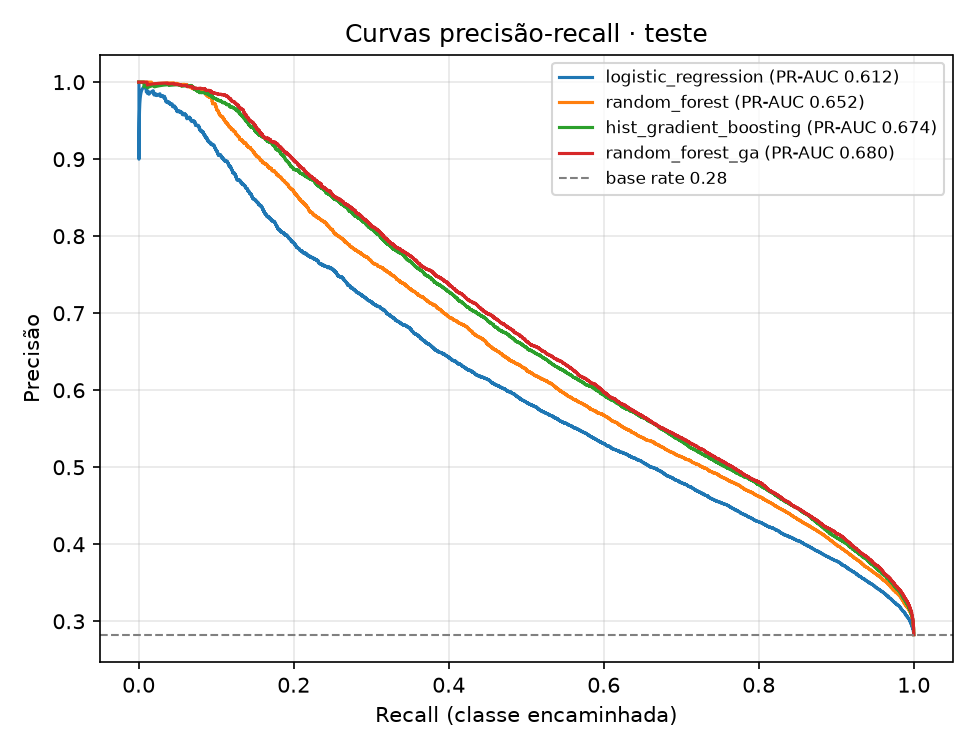

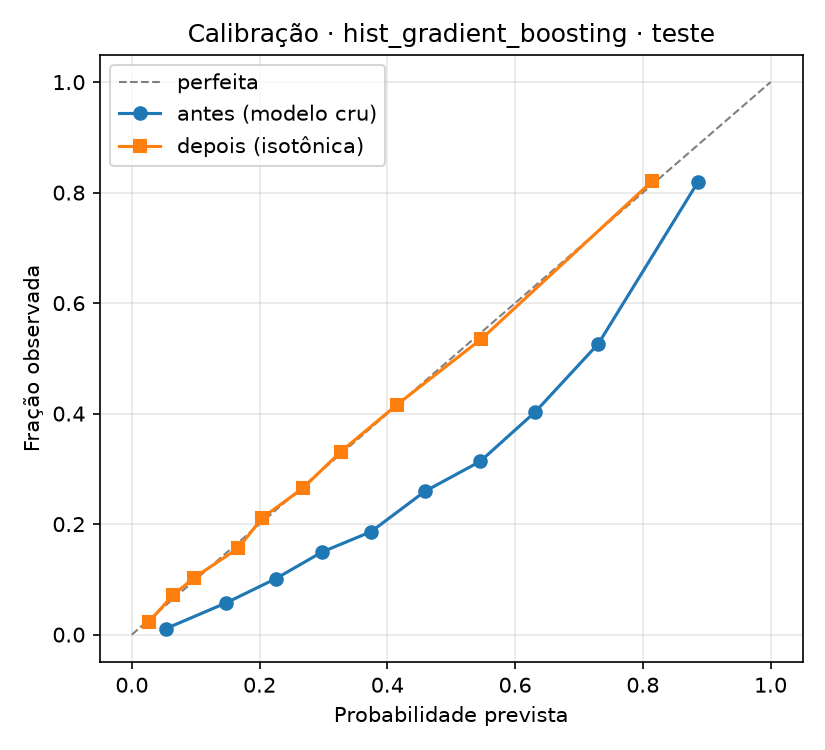

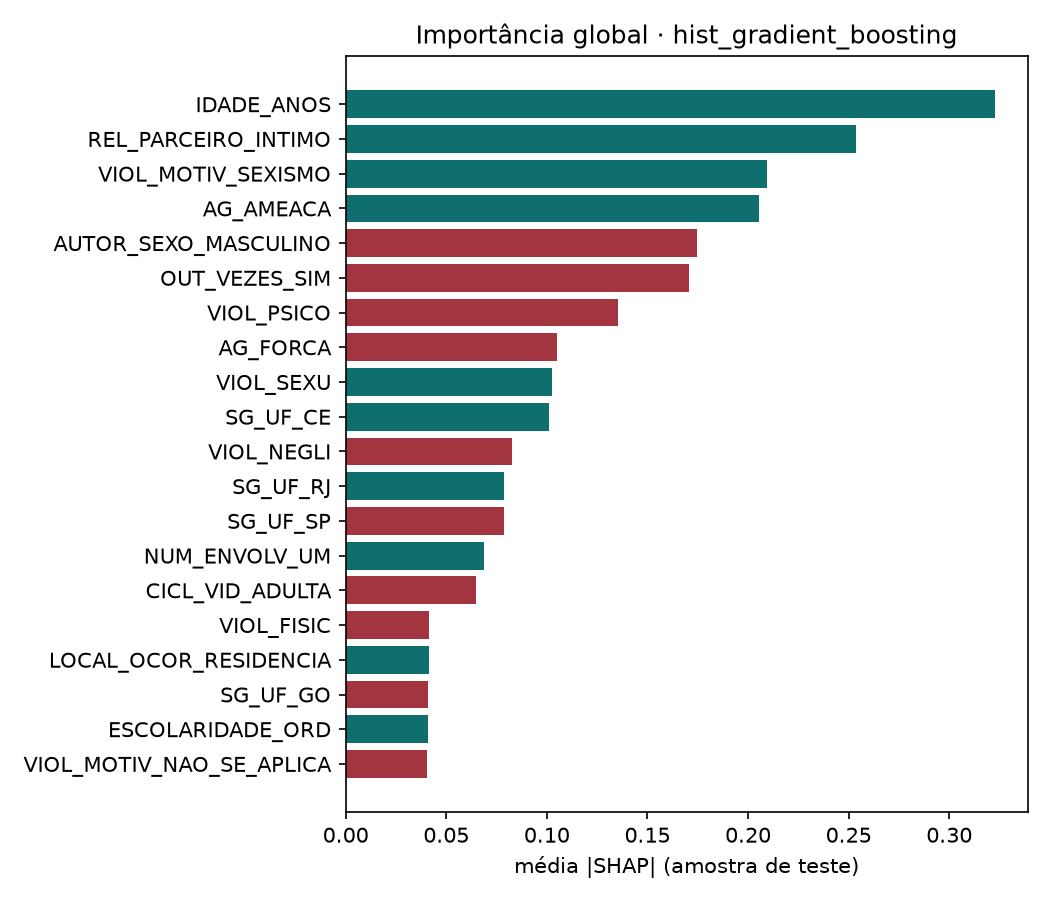

In [7]:
for f in ("pr_curves.png", "calibration.png", "shap_global.png"):
    display(Image(filename=str(ROOT / "docs" / "figures" / f)))

## Calibração e ponto de operação do modelo implantado

In [8]:
sel = metrics["models"][metrics["selected_model"]]
cal = sel["calibration"]
print(f"Brier antes {cal['brier_before']:.4f} → depois {cal['brier_after']:.4f} · limiar calibrado {cal['threshold_calibrated']:.3f}")
pd.Series(cal["test_at_threshold_calibrated"]).round(3)

Brier antes 0.1739 → depois 0.1462 · limiar calibrado 0.150


threshold          0.150
precision          0.392
recall             0.923
f1                 0.551
f2                 0.727
specificity        0.437
accuracy           0.574
tp             21984.000
fp             34036.000
fn              1824.000
tn             26384.000
dtype: float64

## Equidade: recall por raça/cor

In [9]:
pd.DataFrame({g: v for g, v in sel["fairness_by_race"].items() if not g.startswith("_")}).T.round(3)

,n,prevalence,recall,precision,selection_rate
AMARELA,812.0,0.340,0.946,0.449,0.716
BRANCA,31987.0,0.274,0.924,0.371,0.683
IGNORADO,2490.0,0.228,0.873,0.348,0.571
INDIGENA,952.0,0.187,0.770,0.319,0.451
PARDA,39474.0,0.280,0.920,0.406,0.635
PRETA,8513.0,0.347,0.950,0.421,0.784


## Importância global (SHAP) e coeficientes da regressão logística

In [10]:
pd.DataFrame(sel["shap_top20"]).round(4).head(15)

,feature,mean_abs_shap,mean_shap
0,IDADE_ANOS,0.3227,-0.0133
1,REL_PARCEIRO_INTIMO,0.2534,-0.0068
2,VIOL_MOTIV_SEXISMO,0.2093,-0.0197
3,AG_AMEACA,0.2055,-0.0069
4,AUTOR_SEXO_MASCULINO,0.1746,0.0209
5,OUT_VEZES_SIM,0.1707,0.0065
6,VIOL_PSICO,0.1351,0.0111
7,AG_FORCA,0.1048,0.0001
8,VIOL_SEXU,0.1025,-0.0011
9,SG_UF_CE,0.1010,-0.0096


In [11]:
pd.DataFrame(metrics["models"]["logistic_regression"]["coefficient_contributions_top20"]).round(4).head(15)

,feature,mean_abs_shap,mean_shap
0,AG_FORCA,0.1895,0.1895
1,REL_PARCEIRO_INTIMO,0.1750,0.1750
2,VIOL_FISIC,0.1647,-0.1647
3,ESCOLARIDADE_ORD,0.1603,0.1603
4,IDADE_ANOS,0.1582,0.1582
5,DEF_TRANS_NAO,0.1207,-0.1207
6,VIOL_MOTIV_SEXISMO,0.1190,0.1190
7,VIOL_PSICO,0.1144,0.1144
8,AG_AMEACA,0.1135,0.1135
9,AUTOR_SEXO_MASCULINO,0.1077,0.1077


## Impacto dos erros
- **Falso negativo** (modelo não sugere, ficha registrou encaminhamento): a profissional pode deixar de considerar a rede de
  proteção num caso com perfil de risco. É o erro mais caro; por isso o limiar privilegia recall.
- **Falso positivo** (modelo sugere, ficha não registrou): custo de uma conversa a mais com a equipe. Aceitável.
- O modelo reproduz a prática de 2024, inclusive sub-encaminhamento regional. Nunca deve ser usado isoladamente.